In [1]:
print("Hello")

Hello


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (accuracy_score, confusion_matrix , classification_report) 

In [30]:
df = pd.read_csv('Churn_Modelling.csv') 
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [31]:
df.shape

(10000, 14)

In [32]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [34]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [35]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [36]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [37]:
df.drop(columns=['RowNumber' , 'CustomerId' , 'Surname'] , inplace=True) 

/var/folders/zs/vfn5k789363gmxvqm3wzwttw0000gn/T/ipykernel_28288/1477669764.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['RowNumber' , 'CustomerId' , 'Surname'] , inplace=True)


In [38]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')

In [39]:
X = df.drop('Exited' , axis=1) 

y = df['Exited'] 

print("Features : ") 

print(X.head()) 


print("Target :") 

print(y.value_counts())

Features : 
   CreditScore Geography  ...  IsActiveMember  EstimatedSalary
0          619    France  ...               1        101348.88
1          608     Spain  ...               1        112542.58
2          502    France  ...               0        113931.57
3          699    France  ...               0         93826.63
4          850     Spain  ...               1         79084.10

[5 rows x 10 columns]
Target :
Exited
0    7963
1    2037
Name: count, dtype: int64


In [40]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [41]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [43]:
#print(X.columns.tolist())

X = pd.get_dummies(
    X , 
    columns=['Geography' , 'Gender'],
    drop_first=True , 
    dtype=int
)

print("Encoded Features") 
print(X.head()) 

print("New dataset Shape : " , X.shape)

Encoded Features
   CreditScore  Age  ...  Geography_Spain  Gender_Male
0          619   42  ...                0            0
1          608   41  ...                1            0
2          502   42  ...                0            0
3          699   39  ...                0            0
4          850   43  ...                1            0

[5 rows x 11 columns]
New dataset Shape :  (10000, 11)


In [44]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42 ,    stratify=y ) 

print("Training Shape : " , X_train.shape) 

print("Test Shape : " , y_test.shape) 

Training Shape :  (8000, 11)
Test Shape :  (2000,)


In [47]:
scaler = StandardScaler() 



X_train_scaled = scaler.fit_transform(X_train) 

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape : " , X_train_scaled.shape) 

print("Scaled Test Shape : " , X_test_scaled.shape) 



Scaled Training Shape :  (8000, 11)
Scaled Test Shape :  (2000, 11)


In [49]:
model = MLPClassifier(
    hidden_layer_sizes=(16,8),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)

print("Neural Network created succesfully") 

Neural Network created succesfully


In [ ]:
model.fit(X_train_scaled , y_train) 

y_pred = model.predict(X_test_scaled) 

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 0 0 0 0 0 0 0 0]

Predicted Values:
[0 0 0 0 0 0 0 0 1 0]


In [54]:
accuracy = accuracy_score(y_test , y_pred)  


print("accuracy_score : " , accuracy*100)


accuracy_score :  87.25


Confusion Matrix:
[[1551   42]
 [ 213  194]]


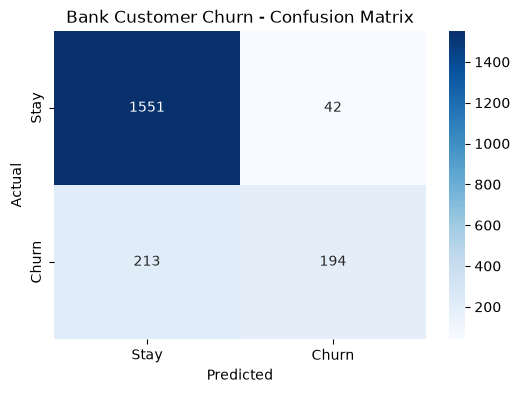

In [55]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stay', 'Churn'],
    yticklabels=['Stay', 'Churn']
)

plt.title("Bank Customer Churn - Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show() 

In [56]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Stay', 'Churn']
    )
)

Classification Report:
              precision    recall  f1-score   support

        Stay       0.88      0.97      0.92      1593
       Churn       0.82      0.48      0.60       407

    accuracy                           0.87      2000
   macro avg       0.85      0.73      0.76      2000
weighted avg       0.87      0.87      0.86      2000

